# Задание 4. Год записи по тембру

Регрессия: по 90 числовым признакам предсказать год. Это поднабор YearPredictionMSD из условия, файлы лежат в `data/songs-prediction-2026`.

Первые 12 признаков в описании UCI — средние тембра, остальные 78 — ковариации. Признаки разного масштаба, пропусков нет, год смещён к 2000-м. Поэтому перед сетью: обрезка редких хвостов, стандартизация, и год тоже приводится к нулевому среднему и единичному разбросу, чтобы шаг Adam был осмысленным. Метрика — RMSE в исходных годах.

Сравнение с самописным Adam из третьего задания идёт на одной и той же MLP и одном и том же разбиении.


In [1]:
%matplotlib inline

import math

import numpy as np
import pandas as pd
import torch
from matplotlib import pyplot as plt
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

DATA_DIR = "data/songs-prediction-2026"
CHECKPOINT = "task4_final.pt"
SUBMISSION = "task4_submission.csv"
FEATURES = [str(i) for i in range(90)]

train_x = pd.read_csv(f"{DATA_DIR}/train_x.csv")
train_y = pd.read_csv(f"{DATA_DIR}/train_y.csv")
test_x = pd.read_csv(f"{DATA_DIR}/test_x.csv")
assert (train_x["Unnamed: 0"].to_numpy() == train_y["Unnamed: 0"].to_numpy()).all()

x_all = train_x[FEATURES].to_numpy(dtype=np.float64)
y_all = train_y["year"].to_numpy(dtype=np.float64)
print("train", x_all.shape, "test", test_x.shape)
print(
    "пропуски",
    int(np.isnan(x_all).sum()),
    int(np.isnan(y_all).sum()),
    int(test_x[FEATURES].isna().sum().sum()),
)
print(train_y["year"].describe().round(2))


train (14000, 90) test (6000, 91)
пропуски 0 0 0
count    14000.00
mean      1998.37
std         11.05
min       1922.00
25%       1994.00
50%       2002.00
75%       2006.00
max       2011.00
Name: year, dtype: float64


## Короткий разбор

Год почти весь сидит в узком окне около 2000, хвост старых записей редкий. Масштаб признаков различается на порядки: медианное стандартное отклонение около 100, а отдельные координаты уходят в тысячи. Линейная связь с годом слабая, сильнее всего у первых тембральных средних.

Числовые id частично пересекаются у train и test. Это не повод подставлять известные годы: колонка train — индекс исходной строки, у теста свой `id` для сабмишена. Метки теста не используются.


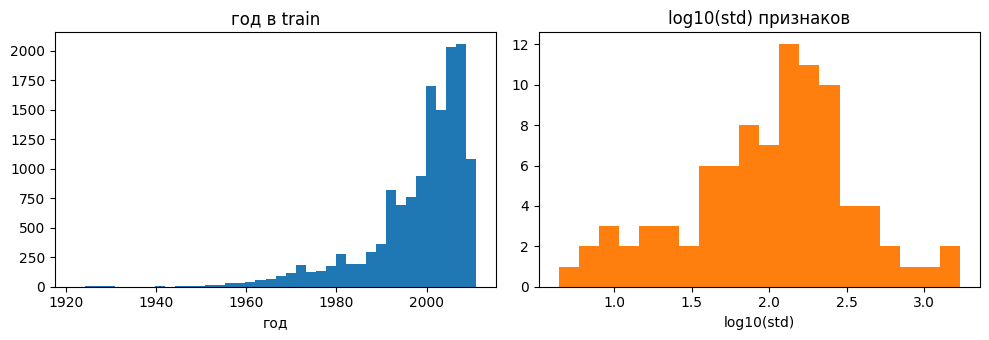

сильнейшие корреляции с годом:
  признак  0  corr +0.231
  признак  5  corr -0.180
  признак  2  corr -0.142
  признак 39  corr -0.135
  признак 62  corr -0.131
  признак  6  corr +0.116
  признак 68  corr -0.111
  признак 46  corr +0.108
std признаков: min 4.4, median 119.7, max 1702.6


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(y_all, bins=40, color="C0")
axes[0].set_title("год в train")
axes[0].set_xlabel("год")
feature_std = x_all.std(axis=0)
axes[1].hist(np.log10(feature_std), bins=20, color="C1")
axes[1].set_title("log10(std) признаков")
axes[1].set_xlabel("log10(std)")
fig.tight_layout()
plt.show()

corr = np.array([np.corrcoef(x_all[:, i], y_all)[0, 1] for i in range(x_all.shape[1])])
order = np.argsort(-np.abs(corr))[:8]
print("сильнейшие корреляции с годом:")
for index in order:
    print(f"  признак {index:2d}  corr {corr[index]:+.3f}")
print(
    "std признаков: min {:.1f}, median {:.1f}, max {:.1f}".format(
        feature_std.min(), np.median(feature_std), feature_std.max()
    )
)


## Предобработка и модель

Обрезка по квантилям 0.1% и 99.9% считается только по обучающей части, затем среднее и std. В сравнение validation не входит в эти статистики. Для финальной модели те же правила пересчитываются уже по всему train.

Сеть — MLP на `torch.nn`: Linear, BatchNorm, ReLU, Dropout, в конце один выход. Рядом линейная модель как нижняя планка. Самописный Adam — тот же класс, что в задании 3: моменты, поправка смещения, без weight decay.


In [3]:
class Adam:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.state = {}

    def zero_grad(self):
        for param in self.params:
            if param.grad is not None:
                param.grad.detach_()
                param.grad.zero_()

    def step(self):
        with torch.no_grad():
            for param in self.params:
                if param.grad is None:
                    continue
                grad = param.grad.detach()
                slot = self.state.get(id(param))
                if slot is None:
                    slot = {
                        "step": 0,
                        "exp_avg": torch.zeros_like(param),
                        "exp_avg_sq": torch.zeros_like(param),
                    }
                    self.state[id(param)] = slot
                if self.weight_decay != 0:
                    grad = grad.add(param, alpha=self.weight_decay)
                slot["step"] += 1
                slot["exp_avg"].mul_(self.beta1).add_(grad, alpha=1 - self.beta1)
                slot["exp_avg_sq"].mul_(self.beta2).addcmul_(grad, grad, value=1 - self.beta2)
                bias_correction1 = 1 - self.beta1 ** slot["step"]
                bias_correction2 = 1 - self.beta2 ** slot["step"]
                denom = slot["exp_avg_sq"].sqrt().div(math.sqrt(bias_correction2)).add(self.eps)
                param.addcdiv_(slot["exp_avg"], denom, value=-self.lr / bias_correction1)


class YearMLP(nn.Module):
    def __init__(self, hidden=(256, 128), dropout=0.1):
        super().__init__()
        layers = []
        previous = 90
        for width in hidden:
            layers += [
                nn.Linear(previous, width),
                nn.BatchNorm1d(width),
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
            previous = width
        layers.append(nn.Linear(previous, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


class YearLinear(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(90, 1)

    def forward(self, x):
        return self.fc(x).squeeze(1)


def prepare(x_fit, x_apply, y_fit):
    low = np.quantile(x_fit, 0.001, axis=0)
    high = np.quantile(x_fit, 0.999, axis=0)
    fit = np.clip(x_fit, low, high)
    mean = fit.mean(axis=0)
    std = fit.std(axis=0)
    std = np.where(std < 1e-8, 1.0, std)
    y_mean = float(y_fit.mean())
    y_std = float(y_fit.std())
    if y_std < 1e-8:
        y_std = 1.0

    def transform(x):
        return ((np.clip(x, low, high) - mean) / std).astype(np.float32)

    stats = {
        "clip_lo": low.astype(np.float32),
        "clip_hi": high.astype(np.float32),
        "x_mean": mean.astype(np.float32),
        "x_std": std.astype(np.float32),
        "y_mean": y_mean,
        "y_std": y_std,
    }
    return transform(x_apply), stats


def target_z(y, stats):
    return ((y - stats["y_mean"]) / stats["y_std"]).astype(np.float32)


def loader(x, y, batch_size, shuffle, seed):
    dataset = TensorDataset(torch.from_numpy(x), torch.from_numpy(y))
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)


def epoch_metrics(model, data_loader, stats, optimizer=None):
    training = optimizer is not None
    model.train(training)
    sse = 0.0
    count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for inputs, targets in data_loader:
            predicted = model(inputs)
            if training:
                loss = nn.functional.mse_loss(predicted, targets)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            diff = (predicted.detach() - targets) * stats["y_std"]
            sse += float(diff.pow(2).sum())
            count += targets.numel()
    return math.sqrt(sse / count)


def fit(model, optimizer, x_train, y_train, x_val, y_val, stats, epochs, seed):
    train_loader = loader(x_train, y_train, 256, True, seed)
    val_loader = loader(x_val, y_val, 512, False, seed)
    history = []
    for epoch in range(1, epochs + 1):
        train_rmse = epoch_metrics(model, train_loader, stats, optimizer)
        val_rmse = epoch_metrics(model, val_loader, stats, None)
        history.append((train_rmse, val_rmse))
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"  epoch {epoch:2d}  train {train_rmse:.3f}  val {val_rmse:.3f}")
    best_epoch = int(np.argmin([item[1] for item in history])) + 1
    return history, best_epoch


## Сравнение на отложенных 20%

Три короткие конфигурации, 20 эпох, шаг `1e-3`, seed 0. Линейный слой и MLP учатся штатным `torch.optim.Adam`. Та же MLP второй раз учится самописным Adam: отличие только в оптимизаторе. Планка «предсказывать медиану train» показывает, выигрыш это или шум.


In [4]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(y_all))
val_size = int(0.2 * len(y_all))
val_idx, tr_idx = perm[:val_size], perm[val_size:]

x_fit, y_fit = x_all[tr_idx], y_all[tr_idx]
x_hold, y_hold = x_all[val_idx], y_all[val_idx]
_, stats_fold = prepare(x_fit, x_fit, y_fit)
x_tr, _ = prepare(x_fit, x_fit, y_fit)
x_va, _ = prepare(x_fit, x_hold, y_fit)
y_tr = target_z(y_fit, stats_fold)
y_va = target_z(y_hold, stats_fold)

median_year = float(np.median(y_fit))
median_rmse = float(np.sqrt(np.mean((y_hold - median_year) ** 2)))
print(f"медиана train -> val RMSE {median_rmse:.3f}")

configs = [
    ("linear / torch Adam", YearLinear, {}, lambda params: torch.optim.Adam(params, lr=1e-3)),
    ("mlp 256-128 / torch Adam", YearMLP, {"hidden": (256, 128), "dropout": 0.1}, lambda params: torch.optim.Adam(params, lr=1e-3)),
    ("mlp 256-128 / свой Adam", YearMLP, {"hidden": (256, 128), "dropout": 0.1}, lambda params: Adam(params, lr=1e-3)),
    ("mlp 384-128 / torch Adam", YearMLP, {"hidden": (384, 128), "dropout": 0.1}, lambda params: torch.optim.Adam(params, lr=1e-3)),
]

comparison = []
for name, factory, kwargs, opt_factory in configs:
    print(name)
    torch.manual_seed(0)
    model = factory(**kwargs)
    optimizer = opt_factory(model.parameters())
    history, best_epoch = fit(model, optimizer, x_tr, y_tr, x_va, y_va, stats_fold, epochs=20, seed=0)
    best_rmse = history[best_epoch - 1][1]
    comparison.append(
        {
            "name": name,
            "factory": factory,
            "kwargs": kwargs,
            "opt_factory": opt_factory,
            "history": history,
            "best_epoch": best_epoch,
            "best_val_rmse": best_rmse,
        }
    )
    print(f"  лучшая эпоха {best_epoch}, val RMSE {best_rmse:.3f}")

pd.DataFrame(
    [
        {
            "model": item["name"],
            "best_epoch": item["best_epoch"],
            "best_val_rmse": item["best_val_rmse"],
            "last_val_rmse": item["history"][-1][1],
        }
        for item in comparison
    ]
)


медиана train -> val RMSE 11.674
linear / torch Adam
  epoch  1  train 11.404  val 10.940
  epoch  5  train 9.984  val 9.933
  epoch 10  train 9.714  val 9.706
  epoch 15  train 9.631  val 9.629
  epoch 20  train 9.602  val 9.610
  лучшая эпоха 19, val RMSE 9.600
mlp 256-128 / torch Adam
  epoch  1  train 10.327  val 9.638
  epoch  5  train 8.558  val 9.387
  epoch 10  train 7.753  val 9.536
  epoch 15  train 7.130  val 9.562
  epoch 20  train 6.675  val 9.708
  лучшая эпоха 4, val RMSE 9.269
mlp 256-128 / свой Adam
  epoch  1  train 10.327  val 9.638
  epoch  5  train 8.558  val 9.387
  epoch 10  train 7.753  val 9.537
  epoch 15  train 7.129  val 9.575
  epoch 20  train 6.677  val 9.719
  лучшая эпоха 4, val RMSE 9.269
mlp 384-128 / torch Adam
  epoch  1  train 10.105  val 9.539
  epoch  5  train 8.403  val 9.469
  epoch 10  train 7.481  val 9.764
  epoch 15  train 6.725  val 9.653
  epoch 20  train 6.198  val 9.710
  лучшая эпоха 4, val RMSE 9.303


,model,best_epoch,best_val_rmse,last_val_rmse
0,linear / torch Adam,19,9.600263,9.610268
1,mlp 256-128 / torch Adam,4,9.268526,9.708119
2,mlp 256-128 / свой Adam,4,9.268646,9.719197
3,mlp 384-128 / torch Adam,4,9.303235,9.709540


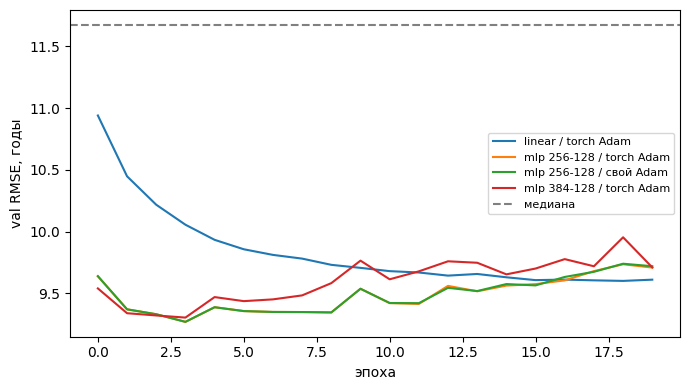

In [5]:
fig, axis = plt.subplots(figsize=(7, 4))
for item in comparison:
    axis.plot([row[1] for row in item["history"]], label=item["name"])
axis.axhline(median_rmse, color="gray", linestyle="--", label="медиана")
axis.set_xlabel("эпоха")
axis.set_ylabel("val RMSE, годы")
axis.legend(fontsize=8)
fig.tight_layout()
plt.show()


## Финальная модель

Берётся конфигурация с лучшим val RMSE. Она учится заново на всём train, число эпох — та, что была лучшей на validation. Стандартизация пересчитывается по всем 14000 строкам. В файл кладутся веса и все числа предобработки. Эта ячейка сама сабмишен не пишет.


In [6]:
winner = min(comparison, key=lambda item: item["best_val_rmse"])
print("финал:", winner["name"], "эпох", winner["best_epoch"])

x_final, stats_full = prepare(x_all, x_all, y_all)
y_final = target_z(y_all, stats_full)
torch.manual_seed(0)
final_model = winner["factory"](**winner["kwargs"])
final_optimizer = winner["opt_factory"](final_model.parameters())
final_loader = loader(x_final, y_final, 256, True, 0)
for epoch in range(1, winner["best_epoch"] + 1):
    train_rmse = epoch_metrics(final_model, final_loader, stats_full, final_optimizer)
    if epoch == 1 or epoch % 5 == 0 or epoch == winner["best_epoch"]:
        print(f"  epoch {epoch:2d}  train RMSE {train_rmse:.3f}")

torch.save(
    {
        "state_dict": final_model.state_dict(),
        "factory_name": winner["factory"].__name__,
        "kwargs": winner["kwargs"],
        **stats_full,
    },
    CHECKPOINT,
)
print("сохранено", CHECKPOINT)


финал: mlp 256-128 / torch Adam эпох 4
  epoch  1  train RMSE 10.202
  epoch  4  train RMSE 8.742
сохранено task4_final.pt


## Сабмишен



In [7]:
checkpoint = torch.load(CHECKPOINT, weights_only=False)
if checkpoint["factory_name"] == "YearLinear":
    predict_model = YearLinear()
else:
    predict_model = YearMLP(**checkpoint["kwargs"])
predict_model.load_state_dict(checkpoint["state_dict"])
predict_model.eval()

raw_test = pd.read_csv(f"{DATA_DIR}/test_x.csv")
test_values = raw_test[FEATURES].to_numpy(dtype=np.float64)
test_values = np.clip(test_values, checkpoint["clip_lo"], checkpoint["clip_hi"])
test_values = (test_values - checkpoint["x_mean"]) / checkpoint["x_std"]
with torch.no_grad():
    predicted_z = predict_model(torch.from_numpy(test_values.astype(np.float32))).numpy()
predicted_year = predicted_z * checkpoint["y_std"] + checkpoint["y_mean"]

submission = pd.DataFrame({"id": raw_test["id"], "year": predicted_year})
submission.to_csv(SUBMISSION, index=False)
print(submission["year"].describe().round(2))
print("строк", len(submission), "файл", SUBMISSION)
submission.head()


count    6000.00
mean     1997.73
std         6.42
min      1972.87
25%      1993.66
50%      1998.96
75%      2002.62
max      2011.24
Name: year, dtype: float64
строк 6000 файл task4_submission.csv


,id,year
0,3416,1998.434448
1,18991,2004.699829
2,11105,1995.253906
3,18902,2001.967896
4,18958,2000.581177


## Итог

Медиана года на validation даёт RMSE 11.67. Линейная сеть доходит до 9.60. MLP 256-128 лучше всех: 9.27 на 4-й эпохе, дальше validation уже растёт, хотя train продолжает падать. Более широкая MLP 384-128 чуть хуже, 9.30.

Свой Adam и 	orch.optim.Adam на одной и той же MLP расходятся только в третьем знаке: 9.269 и 9.269. Шаг совпадает, на этой задаче разницы в качестве нет.

Финальные веса — MLP 256-128, 4 эпохи, стандартизация по всему train. Сабмишен 	ask4_submission.csv: 6000 строк, id и year. Предсказания сжаты к среднему (std около 6.4 при std годов 11), это ожидаемо для короткого обучения до начала переобучения.
